# Fase 4 · KPIs y modelo de riesgo de abandono
**Evento Evaluativo 3 · Análisis de Datos (ITM, 2026-2) · Grupo 2 · Clientes bancarios**

En las fases anteriores entendimos el problema (Fase 1), probamos con estadística qué grupos se van más (Fase 2) y armamos el modelo en estrella (Fase 3). Ahora convertimos todo eso en **indicadores que se pueden vigilar**.

La idea es que el dashboard funcione como el **termómetro del abandono**: cada indicador tiene un número, un semáforo y una acción. Si se enciende en rojo, ya sabemos qué está pasando y qué hacer.

## 1. Qué es un KPI y cómo lo vamos a leer

Un KPI (indicador clave de desempeño) es **un número con significado para una decisión**. No basta con calcularlo: tiene que decirnos si hay un problema. Por eso cada KPI de este proyecto tiene cinco partes:

| Parte | Pregunta que responde |
|---|---|
| Qué mide | ¿Qué es este número, en una frase? |
| Fórmula | ¿Cómo se calcula (y cómo queda en DAX para Power BI)? |
| Semáforo | ¿Desde qué valor es normal, de cuidado o grave? |
| Qué significa si se enciende | ¿Qué está pasando en el negocio? |
| Qué hacer | ¿Qué decisión provoca? |

**De dónde salen los umbrales:** el dataset no trae metas del banco, así que los umbrales son una **propuesta nuestra**. Los fijamos a partir de lo que encontramos en las fases 1 y 2 (la línea base de 20.4 % de abandono y las diferencias entre grupos). En la vida real los definiría el banco; aquí dejamos claro que son supuestos y que se pueden cambiar en un solo lugar (el diccionario `KPIS` más abajo).

**KPI no es lo mismo que gráfico.** El KPI es la medida (se define una sola vez). El gráfico es una forma de mostrarla. La página ejecutiva muestra el valor y el semáforo de cada KPI. Las páginas de detalle usan las mismas medidas cortadas por país, edad, productos o actividad.

## 2. Cargar el modelo de la Fase 3

Leemos las tablas que exportó el notebook 03 y las unimos en una sola vista, **solo para calcular aquí**. En Power BI no se unen: se quedan separadas y conectadas por las relaciones del modelo en estrella.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

RUTA = "../data/processed" if os.path.exists("../data/processed/fact_clientes.csv") else "data/processed"

def leer(nombre):
    return pd.read_csv(f"{RUTA}/{nombre}.csv", encoding="utf-8-sig")

fact = leer("fact_clientes")
dims = {n: leer(f"dim_{n}") for n in ["geografia", "genero", "edad", "antiguedad", "score",
                                      "saldo", "salario", "productos", "actividad", "estado"]}

# Si este notebook ya se ejecutó antes, quitamos las columnas de riesgo para recalcular desde cero
fact = fact.drop(columns=["prob_abandono", "id_riesgo"], errors="ignore")

# Vista plana solo para calcular (no es lo que va a Power BI)
df = fact.copy()
for nombre in ["geografia", "genero", "edad", "antiguedad", "score", "saldo", "salario", "productos", "actividad"]:
    df = df.merge(dims[nombre], on=f"id_{nombre}", how="left")

print("Clientes:", len(df), "| columnas de la vista:", df.shape[1])
assert len(df) == len(fact) == 10000, "El merge cambió el número de filas: revisar llaves"
df[["id_cliente", "pais", "genero", "rango_edad", "productos", "estado_actividad", "rango_saldo", "abandono"]].head()

Clientes: 10000 | columnas de la vista: 36


,id_cliente,pais,genero,rango_edad,productos,estado_actividad,rango_saldo,abandono
0,15634602,Francia,Mujer,41-50,1 producto,Activo,Sin saldo,1
1,15647311,España,Mujer,41-50,1 producto,Activo,Saldo bajo,0
2,15619304,Francia,Mujer,41-50,3 productos,Inactivo,Saldo alto,1
3,15701354,Francia,Mujer,31-40,2 productos,Inactivo,Sin saldo,0
4,15737888,España,Mujer,41-50,1 producto,Activo,Saldo medio,0


## 3. Las ayudas de cálculo

Definimos primero tres cosas pequeñas que usaremos en todos los KPIs: la **tasa de abandono** de un grupo, el **semáforo** y la **definición** de cada KPI (nombre, qué mide, umbrales y qué hacer).

In [2]:
def tasa(sub):
    """Porcentaje de clientes que se fueron dentro de un grupo (valor entre 0 y 1)."""
    return sub["abandono"].mean()

def semaforo(valor, verde_hasta, rojo_desde):
    """Todos nuestros KPIs son 'mientras más alto, peor'.
    Verde: normal. Amarillo: mirar con atención. Rojo: actuar."""
    if valor <= verde_hasta:
        return "🟢 Verde"
    if valor >= rojo_desde:
        return "🔴 Rojo"
    return "🟡 Amarillo"

## 4. Explorar antes de fijar umbrales

Antes de decidir qué es "normal" miramos otra vez los números por grupo. Esto repite lo que ya vimos, pero ahora con una pregunta distinta: **¿desde qué valor un grupo deja de ser normal?**

In [3]:
base = tasa(df)
print(f"Línea base: {base:.1%} de los clientes se fue\n")

resumen = []
for col, titulo in [("pais", "País"), ("rango_edad", "Edad"), ("grupo_productos", "Productos"),
                    ("estado_actividad", "Actividad"), ("genero", "Género"),
                    ("rango_saldo", "Saldo"), ("rango_score", "Score de crédito"),
                    ("rango_salario", "Salario"), ("rango_antiguedad", "Antigüedad")]:
    t = df.groupby(col).agg(clientes=("abandono", "size"), tasa=("abandono", "mean")).reset_index()
    t.columns = ["grupo", "clientes", "tasa"]
    t.insert(0, "variable", titulo)
    resumen.append(t)

resumen = pd.concat(resumen, ignore_index=True)
resumen["tasa"] = (resumen["tasa"] * 100).round(1)
resumen["veces_el_promedio"] = (resumen["tasa"] / (base * 100)).round(2)
resumen

Línea base: 20.4% de los clientes se fue



,variable,grupo,clientes,tasa,veces_el_promedio
0,País,Alemania,2509,32.4,1.59
1,País,España,2477,16.7,0.82
2,País,Francia,5014,16.2,0.80
3,Edad,18-30,1968,7.5,0.37
4,Edad,31-40,4451,12.1,0.59
5,Edad,41-50,2320,34.0,1.67
6,Edad,51-60,797,56.2,2.76
7,Edad,61+,464,24.8,1.22
8,Productos,1 producto,5084,27.7,1.36
9,Productos,2 productos,4590,7.6,0.37


**Qué vemos (datos reales):** la línea base es 20.4 %. Los grupos que más se alejan de ella son:

- **3 o 4 productos:** 85.9 % (4.2 veces el promedio). Son solo 326 clientes.
- **51 a 60 años:** 56.2 % (2.8 veces) y **41 a 50 años:** 34 % (1.7 veces).
- **Alemania:** 32.4 % (1.6 veces).
- **Un solo producto:** 27.7 %, **inactivos:** 26.9 %, **mujeres:** 25.1 %.

En el otro extremo, los clientes con **2 productos** se van muy poco (7.6 %) y los de 18 a 30 años también (7.5 %).

Dos cosas que decidimos con esto:

1. **Para los grupos usaremos "veces el resto" y no "veces el promedio".** El promedio general ya incluye al grupo que estamos mirando (Alemania es el 25 % de la base y sube el promedio). Compararlo contra el resto es más justo.
2. **El saldo no sube de forma ordenada:** sin saldo 13.8 %, bajo 21.5 %, **medio 27.6 %**, alto 23.2 %. Como no es una escalera clara, no lo convertimos en KPI propio. Lo vemos mejor dentro del modelo.

Para ver rápido qué variables mueven la tasa y cuáles no, miramos **la diferencia entre el mejor y el peor grupo** de cada variable.

In [4]:
rango = (resumen.groupby("variable")["tasa"].agg(["min", "max"])
         .assign(diferencia=lambda t: (t["max"] - t["min"]).round(1))
         .sort_values("diferencia", ascending=False))
rango

,min,max,diferencia
variable,,,
Productos,7.6,85.9,78.3
Edad,7.5,56.2,48.7
País,16.2,32.4,16.2
Saldo,13.8,27.6,13.8
Actividad,14.3,26.9,12.6
Género,16.5,25.1,8.6
Score de crédito,18.6,22.0,3.4
Salario,19.9,21.5,1.6
Antigüedad,19.7,21.2,1.5


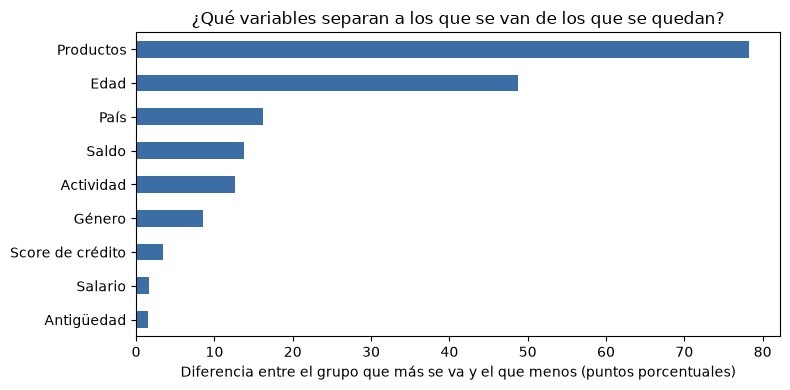

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
rango["diferencia"].sort_values().plot(kind="barh", ax=ax, color="#3b6ea5")
ax.set_xlabel("Diferencia entre el grupo que más se va y el que menos (puntos porcentuales)")
ax.set_ylabel("")
ax.set_title("¿Qué variables separan a los que se van de los que se quedan?")
plt.tight_layout()
plt.show()

**Lectura:** las variables se separan en tres grupos.

- **Mueven mucho la tasa:** productos (78.3 puntos de diferencia) y edad (48.7).
- **La mueven de forma moderada:** país (16.2), saldo (13.8), actividad (12.6) y género (8.6).
- **Casi no la mueven:** score de crédito (3.4), salario (1.6) y antigüedad (1.5).

Esto confirma lo que probamos en la Fase 2 y define qué vigilar. Los KPIs de alerta salen de las variables del primer y segundo grupo. Las del tercer grupo las dejamos como KPI 10 ("lo que no pesa").

## 5. Los KPIs

Con lo anterior fijamos los diez KPIs. Los agrupamos en tres bandas, que serán las tres filas de la página ejecutiva:

- **Termómetro**: ¿qué tan grave está el abandono en total y en dinero?
- **Alertas por grupo**: ¿qué grupos se van más de lo normal? (una por hipótesis)
- **Acción**: ¿a quién hay que llamar?

El KPI 8 (clientes valiosos en riesgo) necesita el modelo de riesgo de la sección 6, así que lo calculamos al final. Dejamos aquí todos los demás.

In [6]:
# Qué es "cliente valioso": el grupo de saldo alto (más de 132,122), definido en la Fase 3
valioso = df["rango_saldo"].eq("Saldo alto")

# Cada KPI: valor, y sus umbrales (verde_hasta, rojo_desde)
alemania   = df["pais"].eq("Alemania")
inactivo   = df["estado_actividad"].eq("Inactivo")
edad_4160  = df["edad"].between(41, 60)
un_prod    = df["num_productos"].eq(1)
tres_mas   = df["num_productos"].ge(3)
mujer      = df["genero"].eq("Mujer")

valores = {
    "K1": tasa(df),
    "K2": df.loc[df["abandono"] == 1, "saldo"].sum() / df["saldo"].sum(),
    "K3": tasa(df[alemania]) / tasa(df[~alemania]),
    "K4": tasa(df[inactivo]) / tasa(df[~inactivo]),
    "K5": tasa(df[edad_4160]),
    "K6": un_prod.mean(),
    "K7": tasa(df[tres_mas]),
    "K9": (tasa(df[mujer]) - tasa(df[~mujer])) * 100,   # en puntos porcentuales
}

KPIS = {
 "K1": dict(banda="Termómetro", nombre="Tasa de abandono", hipotesis="General", unidad="%",
            verde=0.18, rojo=0.22,
            mide="De cada 100 clientes, cuántos se fueron.",
            significa="Si sube del 22 %, el banco pierde clientes más rápido de lo tolerable.",
            accion="Activar el plan de retención en toda la base."),
 "K2": dict(banda="Termómetro", nombre="Saldo en fuga", hipotesis="General", unidad="%",
            verde=0.20, rojo=0.25,
            mide="Del dinero total que el banco administra, qué parte tenían los clientes que se fueron.",
            significa="Si pasa del 25 %, se están yendo los clientes que más dinero tienen, y eso pesa más que el número de clientes.",
            accion="Priorizar retención de clientes de saldo alto."),
 "K3": dict(banda="Alertas por grupo", nombre="Riesgo de Alemania", hipotesis="H2", unidad="veces",
            verde=1.2, rojo=1.5,
            mide="Cuántas veces es más probable que se vaya un cliente de Alemania frente a uno de otro país.",
            significa="Si pasa de 1.5, Alemania tiene un problema propio (no es el mismo comportamiento que el resto).",
            accion="Revisar la oferta y el servicio en Alemania antes de cualquier campaña general."),
 "K4": dict(banda="Alertas por grupo", nombre="Riesgo de inactivos", hipotesis="H3", unidad="veces",
            verde=1.2, rojo=1.5,
            mide="Cuántas veces es más probable que se vaya un cliente inactivo frente a uno activo.",
            significa="Si pasa de 1.5, la inactividad es una señal temprana de fuga.",
            accion="Contactar al cliente cuando deja de usar el banco, antes de que decida irse."),
 "K5": dict(banda="Alertas por grupo", nombre="Abandono de 41 a 60 años", hipotesis="H1", unidad="%",
            verde=0.20, rojo=0.30,
            mide="De cada 100 clientes entre 41 y 60 años, cuántos se fueron.",
            significa="Si pasa del 30 %, el banco no está sirviendo bien a sus clientes de mayor edad.",
            accion="Diseñar un servicio específico para este grupo."),
 "K6": dict(banda="Alertas por grupo", nombre="Clientes con un solo producto", hipotesis="H4", unidad="%",
            verde=0.40, rojo=0.50,
            mide="Qué parte de los clientes tiene solo un producto.",
            significa="Si pasa del 50 %, la mayoría del banco tiene poco vínculo con el cliente, y esos se van más que los de dos productos.",
            accion="Campañas de venta cruzada para llevar clientes de uno a dos productos."),
 "K7": dict(banda="Alertas por grupo", nombre="Abandono con 3 o más productos", hipotesis="H4", unidad="%",
            verde=0.30, rojo=0.50,
            mide="De cada 100 clientes con 3 o 4 productos, cuántos se fueron.",
            significa="Si pasa del 50 %, algo falla en esos productos (no sabemos cuáles, el dataset no lo dice).",
            accion="Investigar esos productos y tratar de entender por qué fallan; no vender más de tres sin entenderlo."),
 "K9": dict(banda="Alertas por grupo", nombre="Brecha de género", hipotesis="Exploración", unidad="puntos",
            verde=3, rojo=6,
            mide="Cuántos puntos porcentuales más se van las mujeres que los hombres.",
            significa="Si pasa de 6 puntos, hay un servicio que está funcionando peor para ellas.",
            accion="Revisar si hay productos o canales que explican la diferencia."),
}

def fmt(valor, unidad):
    if unidad == "%":
        return f"{valor:.1%}"
    if unidad == "veces":
        return f"{valor:.2f} veces"
    return f"{valor:.1f} puntos"

filas = []
for k, d in KPIS.items():
    v = valores[k]
    filas.append({"KPI": k, "Banda": d["banda"], "Nombre": d["nombre"], "Hipótesis": d["hipotesis"],
                  "Valor hoy": fmt(v, d["unidad"]),
                  "Verde hasta": fmt(d["verde"], d["unidad"]), "Rojo desde": fmt(d["rojo"], d["unidad"]),
                  "Semáforo": semaforo(v, d["verde"], d["rojo"])})
tabla_kpi = pd.DataFrame(filas)
tabla_kpi

,KPI,Banda,Nombre,Hipótesis,Valor hoy,Verde hasta,Rojo desde,Semáforo
0,K1,Termómetro,Tasa de abandono,General,20.4%,18.0%,22.0%,🟡 Amarillo
1,K2,Termómetro,Saldo en fuga,General,24.3%,20.0%,25.0%,🟡 Amarillo
2,K3,Alertas por grupo,Riesgo de Alemania,H2,1.99 veces,1.20 veces,1.50 veces,🔴 Rojo
3,K4,Alertas por grupo,Riesgo de inactivos,H3,1.88 veces,1.20 veces,1.50 veces,🔴 Rojo
4,K5,Alertas por grupo,Abandono de 41 a 60 años,H1,39.7%,20.0%,30.0%,🔴 Rojo
5,K6,Alertas por grupo,Clientes con un solo producto,H4,50.8%,40.0%,50.0%,🔴 Rojo
6,K7,Alertas por grupo,Abandono con 3 o más productos,H4,85.9%,30.0%,50.0%,🔴 Rojo
7,K9,Alertas por grupo,Brecha de género,Exploración,8.6 puntos,3.0 puntos,6.0 puntos,🔴 Rojo


**Lectura de los semáforos:**

- **Termómetro en amarillo.** La tasa de abandono (20.4 %) y el saldo en fuga (24.3 %) están en amarillo. El saldo en fuga está a menos de un punto del rojo (25 %) y es más alto que la tasa de clientes: **se va una parte mayor del dinero que de las personas**. Es la señal más importante del termómetro.
- **Alertas por grupo en rojo.** Alemania (1.99 veces), inactivos (1.88 veces), 41 a 60 años (39.7 %), tres o más productos (85.9 %) y brecha de género (8.6 puntos) están por encima de su umbral rojo.
- **Un solo producto (50.8 %)** apenas pasa el umbral rojo (50 %). Lo decimos con honestidad en el video: es un caso de frontera, no un valor extremo.

**Una advertencia importante:** que casi todo salga en rojo no significa que el banco esté colapsando. Los KPIs por grupo están diseñados para encender donde hay concentración de abandono, y los umbrales los pusimos nosotros. Su utilidad real aparece en el dashboard: al filtrar (por ejemplo, solo Francia o solo clientes de 18 a 30 años) los semáforos cambian y se ve dónde el problema es grave y dónde no.

### Gráfico de los semáforos

Mostramos cada KPI como "cuántas veces está sobre su umbral rojo". Así los KPIs que tienen unidades distintas (%, veces, puntos) se pueden comparar en la misma escala: **1.0 es el borde del rojo**; si pasa de 1.0, está en rojo.

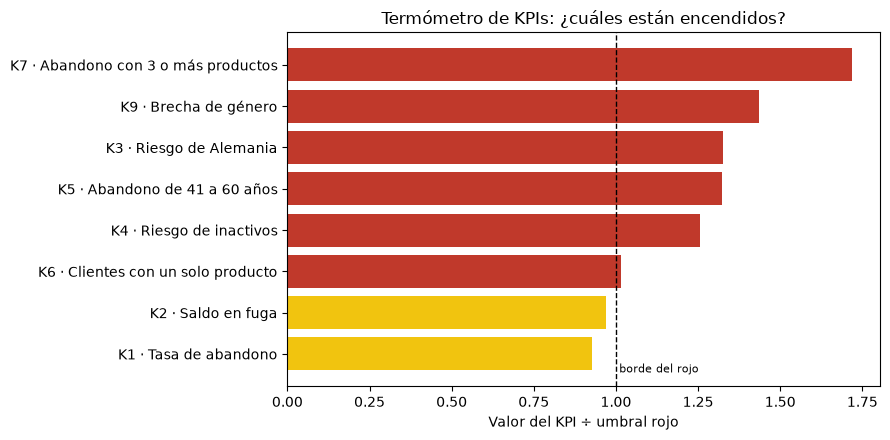

In [7]:
rel = pd.Series({k: valores[k] / KPIS[k]["rojo"] for k in KPIS}, name="sobre_rojo")
rel.index = [f"{k} · {KPIS[k]['nombre']}" for k in rel.index]
rel = rel.sort_values()

colores = ["#c0392b" if v >= 1 else ("#f1c40f" if v > (KPIS[k.split(' ·')[0]]['verde'] / KPIS[k.split(' ·')[0]]['rojo']) else "#27ae60")
           for k, v in rel.items()]

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(rel.index, rel.values, color=colores)
ax.axvline(1, color="black", linestyle="--", linewidth=1)
ax.text(1.01, -0.45, "borde del rojo", fontsize=8)
ax.set_xlabel("Valor del KPI ÷ umbral rojo")
ax.set_title("Termómetro de KPIs: ¿cuáles están encendidos?")
plt.tight_layout()
plt.show()

**Cómo leerlo:** todo lo que pasa de la línea punteada está en rojo. Las barras más largas son las más urgentes: **tres o más productos**, **brecha de género** y **abandono de 41 a 60 años**. Los dos del termómetro (tasa de abandono y saldo en fuga) quedan justo debajo de la línea: no están en rojo, pero están cerca.

## 6. Modelo de riesgo: ¿a quién hay que llamar?

Los KPIs anteriores dicen **qué grupos** se van. Para actuar necesitamos saber **qué clientes en concreto** están en riesgo. Para eso entrenamos un modelo que, con los datos de cada cliente, calcula la probabilidad de que se vaya. Ese número lo llamamos **riesgo del cliente**.

Esto es lo que lleva el análisis un paso más allá de lo descriptivo: en lugar de solo decir que "los alemanes se van más", entregamos una lista priorizada.

**Qué modelo vamos a usar.** Probamos tres y decidimos con los números:

| Modelo | Por qué lo probamos |
|---|---|
| Regresión logística | Es el más fácil de explicar. Nos sirve de punto de comparación |
| Random Forest | Muchos árboles de decisión que votan. Detecta combinaciones (por ejemplo, edad y productos juntos) |
| Gradient Boosting | Árboles que se corrigen entre sí. Suele ser el más preciso en datos de tabla |

**Cuidado con las trampas.** Evaluamos cada modelo con datos que **no vio al aprender** (25 % de los clientes apartados). Si lo evaluáramos con los mismos datos del entrenamiento, el número saldría inflado.

In [8]:
from sklearn.model_selection import train_test_split, cross_val_predict, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, precision_score, recall_score, roc_curve

# Variables del modelo: las originales + las señales que encontramos en la Fase 2
X = pd.DataFrame({
    "edad": df["edad"],
    "anios_cliente": df["anios_cliente"],
    "puntaje_credito": df["puntaje_credito"],
    "saldo": df["saldo"],
    "salario_estimado": df["salario_estimado"],
    "num_productos": df["num_productos"],
    "es_activo": df["es_activo"],
    "tiene_tarjeta": df["tiene_tarjeta"],
    "es_alemania": (df["pais"] == "Alemania").astype(int),
    "es_espana": (df["pais"] == "España").astype(int),
    "es_mujer": (df["genero"] == "Mujer").astype(int),
    "tiene_3_o_mas_productos": (df["num_productos"] >= 3).astype(int),
    "tiene_1_producto": (df["num_productos"] == 1).astype(int),
    "edad_41_a_60": df["edad"].between(41, 60).astype(int),
    "sin_saldo": (df["saldo"] == 0).astype(int),
})
y = df["abandono"]

X_ent, X_prueba, y_ent, y_prueba = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
print(f"Entrenamiento: {len(X_ent)} clientes | Prueba: {len(X_prueba)} clientes")
print(f"Tasa de abandono en entrenamiento: {y_ent.mean():.1%} | en prueba: {y_prueba.mean():.1%} (parecidas a propósito: 'stratify')")

Entrenamiento: 7500 clientes | Prueba: 2500 clientes
Tasa de abandono en entrenamiento: 20.4% | en prueba: 20.4% (parecidas a propósito: 'stratify')


In [9]:
modelos = {
    "Regresión logística": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=20, random_state=42, n_jobs=1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
}

resultados = []
probs_prueba = {}
for nombre, modelo in modelos.items():
    modelo.fit(X_ent, y_ent)
    p = modelo.predict_proba(X_prueba)[:, 1]
    probs_prueba[nombre] = p
    resultados.append({
        "Modelo": nombre,
        "AUC": round(roc_auc_score(y_prueba, p), 3),
        "Precisión (corte 0.5)": round(precision_score(y_prueba, p >= 0.5), 2),
        "Cobertura (corte 0.5)": round(recall_score(y_prueba, p >= 0.5), 2),
        "Precisión (corte 0.3)": round(precision_score(y_prueba, p >= 0.3), 2),
        "Cobertura (corte 0.3)": round(recall_score(y_prueba, p >= 0.3), 2),
    })
pd.DataFrame(resultados).set_index("Modelo")

,AUC,Precisión (corte 0.5),Cobertura (corte 0.5),Precisión (corte 0.3),Cobertura (corte 0.3)
Modelo,,,,,
Regresión logística,0.857,0.79,0.48,0.58,0.66
Random Forest,0.874,0.81,0.47,0.61,0.67
Gradient Boosting,0.879,0.80,0.51,0.63,0.66


**Resultados en datos que el modelo no vio:**

- Los tres modelos son **buenos y parecidos**: AUC entre 0.857 y 0.879.
- El Gradient Boosting tiene el mejor AUC (0.879), aunque solo 0.02 más que la regresión logística. Esa poca diferencia es una buena noticia: significa que el patrón es claro y no depende de un modelo complicado.
- Con corte en 0.5, el modelo acierta cerca de 8 de cada 10 clientes que marca, pero solo atrapa a la mitad de los que se van.
- Con corte en 0.3, atrapa cerca de 2 de cada 3 de los que se van, pero 4 de cada 10 clientes marcados eran falsas alarmas.

Por eso no usamos un solo corte: en la sección 7 definimos tres niveles de riesgo.

**Cómo leer las métricas** (con palabras simples):

- **AUC**: si tomo al azar un cliente que se fue y uno que se quedó, qué tan seguido el modelo le da más riesgo al que se fue. 0.5 es tirar una moneda; 1.0 es perfecto.
- **Precisión**: de los clientes que el modelo marca como en riesgo, cuántos de verdad se fueron.
- **Cobertura**: de los clientes que de verdad se fueron, cuántos alcanzó a marcar el modelo.
- **El corte** es el riesgo desde el cual marcamos a alguien. Un corte bajo (0.3) atrapa más clientes pero con más falsas alarmas; uno alto (0.5) acierta más pero deja escapar a más.

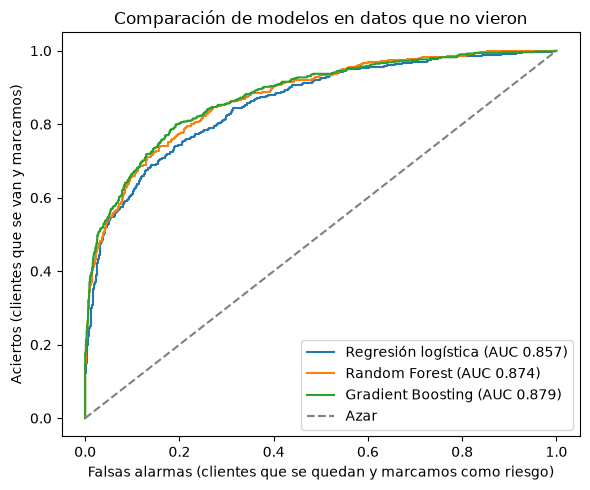

In [10]:
fig, ax = plt.subplots(figsize=(6, 5))
for nombre, p in probs_prueba.items():
    fpr, tpr, _ = roc_curve(y_prueba, p)
    ax.plot(fpr, tpr, label=f"{nombre} (AUC {roc_auc_score(y_prueba, p):.3f})")
ax.plot([0, 1], [0, 1], "--", color="gray", label="Azar")
ax.set_xlabel("Falsas alarmas (clientes que se quedan y marcamos como riesgo)")
ax.set_ylabel("Aciertos (clientes que se van y marcamos)")
ax.set_title("Comparación de modelos en datos que no vieron")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Lectura:** las tres curvas están lejos de la diagonal (azar) y muy pegadas entre sí. Ningún modelo gana por mucho, así que la elección final se basa en el AUC y no en una diferencia dramática.

### ¿Qué pesa más para el modelo?

Si el modelo funciona, debería confirmar lo que ya vimos en la Fase 2. Medimos la importancia por permutación: se desordena una variable y se mira cuánto empeora el modelo. Si empeora mucho, esa variable importaba.

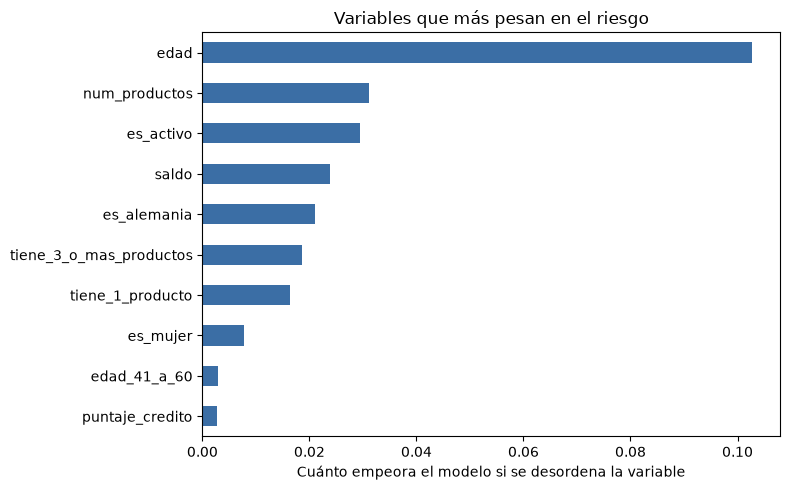

edad                       0.1028
num_productos              0.0312
es_activo                  0.0295
saldo                      0.0239
es_alemania                0.0210
tiene_3_o_mas_productos    0.0187
tiene_1_producto           0.0163
es_mujer                   0.0078
edad_41_a_60               0.0030
puntaje_credito            0.0027
Name: caída del AUC al desordenar, dtype: float64

In [11]:
from sklearn.inspection import permutation_importance

ganador = modelos["Gradient Boosting"]
imp = permutation_importance(ganador, X_prueba, y_prueba, scoring="roc_auc", n_repeats=10, random_state=42, n_jobs=1)
imp_tabla = (pd.Series(imp.importances_mean, index=X.columns)
             .sort_values(ascending=False).round(4).rename("caída del AUC al desordenar"))

fig, ax = plt.subplots(figsize=(8, 5))
imp_tabla.head(10).sort_values().plot(kind="barh", ax=ax, color="#3b6ea5")
ax.set_xlabel("Cuánto empeora el modelo si se desordena la variable")
ax.set_title("Variables que más pesan en el riesgo")
plt.tight_layout()
plt.show()
imp_tabla.head(10)

**Qué dice el modelo:**

- **La edad pesa mucho más que todo lo demás:** al desordenarla, el AUC cae 0.103, tres veces más que cualquier otra variable.
- Siguen **número de productos (0.032)**, **actividad (0.030)**, **saldo (0.024)** y **Alemania (0.021)**.
- **Score de crédito (0.003)** casi no pesa, igual que en los KPIs.
- `edad_41_a_60` pesa poco (0.003) porque la variable `edad` ya contiene esa información. No es que el grupo no importe.

Esto confirma las hipótesis H1 a H4 con otro método. Una cosa nueva: el **saldo** sí tiene peso en el modelo aunque no se vio claro en los grupos. Una explicación posible (que no probamos) es que los clientes alemanes concentran saldos más altos (en promedio unos 120 mil, frente a unos 62 mil en Francia) y el modelo usa el saldo junto con el país.

### Decisión del modelo

Elegimos **Gradient Boosting** como modelo final porque tuvo el mejor AUC en datos de prueba. La regresión logística queda como respaldo: tiene resultados muy cercanos y es más fácil de explicar, pero el Gradient Boosting aprovecha mejor las combinaciones.

## 7. Riesgo para cada cliente

Para tener un riesgo de **todos** los clientes (no solo del 25 % de prueba) usamos validación cruzada: se divide la base en 5 partes, y el riesgo de cada parte lo calcula un modelo que **no la vio al aprender**. Así nadie queda con un riesgo "memorizado".

In [12]:
validacion = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
riesgo = cross_val_predict(GradientBoostingClassifier(random_state=42), X, y, cv=validacion, method="predict_proba")[:, 1]
df["prob_abandono"] = riesgo.round(4)

print("AUC con validación cruzada (todos los clientes):", round(roc_auc_score(y, riesgo), 3))
df["prob_abandono"].describe().round(3)

AUC con validación cruzada (todos los clientes): 0.865


count    10000.000
mean         0.203
std          0.239
min          0.006
25%          0.048
50%          0.106
75%          0.243
max          0.994
Name: prob_abandono, dtype: float64

### Niveles de riesgo

Un riesgo de 0.37 es difícil de explicar a un gerente. Lo convertimos en tres niveles. Probamos varios cortes y validamos con la tasa de abandono real de cada nivel, que debe subir de un nivel al siguiente:

In [13]:
CORTE_MEDIO, CORTE_ALTO = 0.20, 0.50

def nivel(p):
    if p >= CORTE_ALTO:
        return "Alto"
    if p >= CORTE_MEDIO:
        return "Medio"
    return "Bajo"

df["nivel_riesgo"] = df["prob_abandono"].apply(nivel)

validacion_niveles = (df.groupby("nivel_riesgo")
                      .agg(clientes=("abandono", "size"), se_fueron=("abandono", "sum"), tasa_real=("abandono", "mean"))
                      .reindex(["Bajo", "Medio", "Alto"]))
validacion_niveles["% de clientes"] = (validacion_niveles["clientes"] / len(df) * 100).round(1)
validacion_niveles["tasa_real"] = (validacion_niveles["tasa_real"] * 100).round(1)
validacion_niveles

,clientes,se_fueron,tasa_real,% de clientes
nivel_riesgo,,,,
Bajo,7010,513,7.3,70.1
Medio,1734,561,32.4,17.3
Alto,1256,963,76.7,12.6


**Los niveles funcionan:** la tasa real sube de forma ordenada de un nivel al siguiente.

| Nivel | Clientes | % de la base | Se fue de verdad |
|---|---|---|---|
| Bajo | 7,010 | 70.1 % | 7.3 % |
| Medio | 1,734 | 17.3 % | 32.4 % |
| Alto | 1,256 | 12.6 % | 76.7 % |

Del nivel Alto se fue el 76.7 %, y ese nivel concentra 963 de los 2,037 clientes que se fueron (cerca de la mitad) con solo el 12.6 % de la base. Los niveles cortan donde la tasa real se duplica o más de un nivel a otro (0.20 y 0.50). El nivel Bajo no es cero riesgo: aun ahí se fue el 7.3 %.

Los números pueden variar un poco si otra versión de scikit-learn calcula el modelo distinto, pero el orden de los niveles se mantiene.

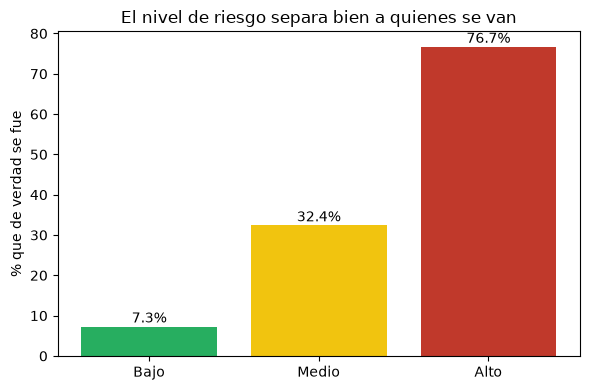

In [14]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(validacion_niveles.index, validacion_niveles["tasa_real"], color=["#27ae60", "#f1c40f", "#c0392b"])
for i, v in enumerate(validacion_niveles["tasa_real"]):
    ax.text(i, v + 1, f"{v}%", ha="center")
ax.set_ylabel("% que de verdad se fue")
ax.set_title("El nivel de riesgo separa bien a quienes se van")
plt.tight_layout()
plt.show()

### KPI 8 · Clientes valiosos en riesgo

Con los niveles ya podemos calcular el KPI de acción: **de los clientes que todavía están con el banco, cuánto dinero tienen los que tienen riesgo alto.** Es el dinero que se puede salvar si se llama a tiempo.

In [15]:
siguen = df["abandono"] == 0
alto = df["nivel_riesgo"] == "Alto"

llamar = df[siguen & alto]
saldo_en_riesgo = llamar["saldo"].sum()
valioso_en_riesgo = df[siguen & alto & valioso]

valores["K8"] = saldo_en_riesgo / df.loc[siguen, "saldo"].sum()
KPIS["K8"] = dict(banda="Acción", nombre="Saldo en riesgo alto (clientes que siguen)", hipotesis="Modelo", unidad="%",
                  verde=0.05, rojo=0.10,
                  mide="De todo el dinero de los clientes que siguen, qué parte está en manos de clientes con riesgo alto de irse.",
                  significa="Si pasa del 10 %, hay mucho dinero que se puede perder en el corto plazo.",
                  accion="Entregar al equipo comercial la lista de clientes de riesgo alto, empezando por los de saldo alto.")

print(f"Clientes que siguen con riesgo alto: {len(llamar)}")
print(f"  de ellos, con saldo alto: {len(valioso_en_riesgo)}")
print(f"Saldo en riesgo alto: {saldo_en_riesgo:,.0f}")
print(f"KPI 8: {valores['K8']:.1%} del saldo de quienes siguen")

lista = (llamar.sort_values(["rango_saldo", "prob_abandono"], ascending=[True, False])
         [["id_cliente", "apellido", "pais", "rango_edad", "productos", "estado_actividad", "saldo", "prob_abandono"]]
         .sort_values(["prob_abandono"], ascending=False).head(10))
lista

Clientes que siguen con riesgo alto: 293
  de ellos, con saldo alto: 75
Saldo en riesgo alto: 27,792,176
KPI 8: 4.8% del saldo de quienes siguen


,id_cliente,apellido,pais,rango_edad,productos,estado_actividad,saldo,prob_abandono
313,15797960,Skinner,Alemania,51-60,1 producto,Inactivo,135296.33,0.9711
8553,15791321,Nwora,España,51-60,1 producto,Inactivo,0.00,0.9661
5607,15771728,Mackenzie,Alemania,41-50,3 productos,Inactivo,104405.54,0.9602
8156,15785576,Mayrhofer,Alemania,61+,1 producto,Inactivo,119496.87,0.9600
8188,15623314,Tucker,Alemania,51-60,1 producto,Inactivo,190353.08,0.9494
4396,15691119,Martin,Alemania,61+,1 producto,Inactivo,136525.99,0.9346
5465,15794941,Chibueze,Alemania,41-50,3 productos,Inactivo,85906.65,0.9260
7803,15691504,Yusupova,Alemania,51-60,1 producto,Inactivo,124099.13,0.9116
4886,15657468,Simmons,Alemania,51-60,1 producto,Inactivo,123805.03,0.9113
7862,15811343,Cattaneo,Alemania,31-40,3 productos,Activo,161591.11,0.8973


**Resultado:** hay **293 clientes que siguen en el banco con riesgo alto**. De ellos, 75 tienen saldo alto. Entre todos tienen cerca de 27.8 millones, que son el **4.8 % del saldo** de quienes siguen. Con el umbral que propusimos (verde hasta 5 %), el semáforo queda en verde, muy cerca del borde.

Lo importante no es el color sino el tamaño de la tarea: **293 llamadas es una lista que un equipo comercial puede atender en una semana.** La tabla de arriba muestra los 10 con mayor riesgo; son sobre todo clientes alemanes, inactivos, de 41 años en adelante.

Un dato que hay que decir con cuidado: de los 1,256 clientes de riesgo alto, 963 ya se habían ido. Eso es lo que esperamos de un modelo que funciona, pero también quiere decir que los 293 que quedan son los que **todavía se pueden salvar**.

### KPI 10 · Lo que no pesa

Es un KPI "inverso": en lugar de alertar, **descarta**. Muestra las variables donde la diferencia entre el mejor y el peor grupo es pequeña. Sirve para decir con datos que una campaña basada en el score, el salario o la antigüedad no tiene soporte.

In [16]:
no_pesan = rango.loc[["Score de crédito", "Salario", "Antigüedad"], ["min", "max", "diferencia"]]
no_pesan.columns = ["Grupo que menos se va (%)", "Grupo que más se va (%)", "Diferencia (puntos)"]
no_pesan

,Grupo que menos se va (%),Grupo que más se va (%),Diferencia (puntos)
variable,,,
Score de crédito,18.6,22.0,3.4
Salario,19.9,21.5,1.6
Antigüedad,19.7,21.2,1.5


**Lectura:** entre el mejor y el peor grupo de score hay 3.4 puntos de diferencia; en salario, 1.6; en antigüedad, 1.5. Comparado con 78 puntos en productos o 49 en edad, son diferencias pequeñas.

**Qué decisión deja:** una campaña de retención dirigida por nivel de ingreso, score o años como cliente no tiene respaldo en los datos. El esfuerzo debe ir a edad, productos, actividad y país.

## 8. Medidas DAX para Power BI

Las medidas DAX son las fórmulas que Power BI calcula en vivo y que cambian cuando el usuario usa un filtro. Se crean en una tabla vacía llamada `_Medidas` (se crea con *Entrada de datos* y se deja sin columnas útiles). Así todas las medidas quedan juntas y ordenadas.

Los nombres de las tablas y las columnas son los de la Fase 3.

```dax
-- Bloque 1 · Base
Clientes = COUNTROWS ( fact_clientes )
Clientes Perdidos = SUM ( fact_clientes[abandono] )
Clientes Activos del Banco = [Clientes] - [Clientes Perdidos]
Tasa Abandono = DIVIDE ( [Clientes Perdidos], [Clientes] )
Saldo Total = SUM ( fact_clientes[saldo] )
Saldo Fugado = CALCULATE ( SUM ( fact_clientes[saldo] ), fact_clientes[abandono] = 1 )

-- K1 · Tasa de abandono
KPI1 Tasa Abandono = [Tasa Abandono]

-- K2 · Saldo en fuga
KPI2 Saldo en Fuga = DIVIDE ( [Saldo Fugado], [Saldo Total] )

-- K3 · Riesgo de Alemania (siempre compara contra el resto, aunque se filtre otro país)
Tasa Alemania =
CALCULATE ( [Tasa Abandono], REMOVEFILTERS ( dim_geografia ), dim_geografia[pais] = "Alemania" )
Tasa Resto Paises =
CALCULATE ( [Tasa Abandono], REMOVEFILTERS ( dim_geografia ), dim_geografia[pais] <> "Alemania" )
KPI3 Riesgo Alemania = DIVIDE ( [Tasa Alemania], [Tasa Resto Paises] )

-- K4 · Riesgo de inactivos
Tasa Inactivos =
CALCULATE ( [Tasa Abandono], REMOVEFILTERS ( dim_actividad ), dim_actividad[estado_actividad] = "Inactivo" )
Tasa Activos =
CALCULATE ( [Tasa Abandono], REMOVEFILTERS ( dim_actividad ), dim_actividad[estado_actividad] = "Activo" )
KPI4 Riesgo Inactivos = DIVIDE ( [Tasa Inactivos], [Tasa Activos] )

-- K5 · Abandono de 41 a 60 años
KPI5 Abandono 41 a 60 =
CALCULATE ( [Tasa Abandono], REMOVEFILTERS ( dim_edad ), dim_edad[rango_edad] IN { "41-50", "51-60" } )

-- K6 · Clientes con un solo producto
KPI6 Pct Un Producto =
DIVIDE (
    CALCULATE ( [Clientes], REMOVEFILTERS ( dim_productos ), dim_productos[productos] = "1 producto" ),
    CALCULATE ( [Clientes], REMOVEFILTERS ( dim_productos ) )
)

-- K7 · Abandono con 3 o más productos
KPI7 Abandono 3 o Mas Productos =
CALCULATE ( [Tasa Abandono], REMOVEFILTERS ( dim_productos ), dim_productos[grupo_productos] = "3 o 4 productos" )

-- K8 · Saldo en riesgo alto (de quienes siguen)
Saldo Riesgo Alto =
CALCULATE ( SUM ( fact_clientes[saldo] ), dim_riesgo[nivel_riesgo] = "Alto", fact_clientes[abandono] = 0 )
Saldo de Quienes Siguen = CALCULATE ( SUM ( fact_clientes[saldo] ), fact_clientes[abandono] = 0 )
KPI8 Saldo en Riesgo Alto = DIVIDE ( [Saldo Riesgo Alto], [Saldo de Quienes Siguen] )
Clientes a Llamar =
CALCULATE ( [Clientes], dim_riesgo[nivel_riesgo] = "Alto", fact_clientes[abandono] = 0 )
Valiosos a Llamar =
CALCULATE ( [Clientes], dim_riesgo[nivel_riesgo] = "Alto", fact_clientes[abandono] = 0, dim_saldo[rango_saldo] = "Saldo alto" )

-- K9 · Brecha de género (en puntos porcentuales)
KPI9 Brecha Genero Puntos =
( CALCULATE ( [Tasa Abandono], REMOVEFILTERS ( dim_genero ), dim_genero[genero] = "Mujer" )
- CALCULATE ( [Tasa Abandono], REMOVEFILTERS ( dim_genero ), dim_genero[genero] = "Hombre" ) ) * 100

-- Semáforos (devuelven un texto que se usa en formato condicional)
Semaforo K1 = SWITCH ( TRUE (), [KPI1 Tasa Abandono] >= 0.22, "Rojo", [KPI1 Tasa Abandono] <= 0.18, "Verde", "Amarillo" )
Semaforo K2 = SWITCH ( TRUE (), [KPI2 Saldo en Fuga] >= 0.25, "Rojo", [KPI2 Saldo en Fuga] <= 0.20, "Verde", "Amarillo" )
Semaforo K3 = SWITCH ( TRUE (), [KPI3 Riesgo Alemania] >= 1.5, "Rojo", [KPI3 Riesgo Alemania] <= 1.2, "Verde", "Amarillo" )
Semaforo K4 = SWITCH ( TRUE (), [KPI4 Riesgo Inactivos] >= 1.5, "Rojo", [KPI4 Riesgo Inactivos] <= 1.2, "Verde", "Amarillo" )
Semaforo K5 = SWITCH ( TRUE (), [KPI5 Abandono 41 a 60] >= 0.30, "Rojo", [KPI5 Abandono 41 a 60] <= 0.20, "Verde", "Amarillo" )
Semaforo K6 = SWITCH ( TRUE (), [KPI6 Pct Un Producto] >= 0.50, "Rojo", [KPI6 Pct Un Producto] <= 0.40, "Verde", "Amarillo" )
Semaforo K7 = SWITCH ( TRUE (), [KPI7 Abandono 3 o Mas Productos] >= 0.50, "Rojo", [KPI7 Abandono 3 o Mas Productos] <= 0.30, "Verde", "Amarillo" )
Semaforo K8 = SWITCH ( TRUE (), [KPI8 Saldo en Riesgo Alto] >= 0.10, "Rojo", [KPI8 Saldo en Riesgo Alto] <= 0.05, "Verde", "Amarillo" )
Semaforo K9 = SWITCH ( TRUE (), [KPI9 Brecha Genero Puntos] >= 6, "Rojo", [KPI9 Brecha Genero Puntos] <= 3, "Verde", "Amarillo" )
```

**Una advertencia sobre el filtro.** `REMOVEFILTERS` hace que los KPIs de grupo (Alemania, inactivos, edad, productos) no cambien si el usuario filtra esa misma dimensión. Es a propósito: la alerta compara siempre contra el resto. Los demás filtros (por ejemplo, género o rango de saldo) sí los afectan.

**Una limitación del semáforo.** Los umbrales están escritos dentro de cada medida `Semaforo`. Si el banco cambia una meta, hay que editar la medida. Para el proyecto es suficiente; en producción se pondrían los umbrales en una tabla de parámetros.

## 9. Exportar para Power BI

Guardamos tres cosas:

1. `dim_riesgo.csv`: la nueva dimensión con los tres niveles. Se conecta a la tabla de hechos con `id_riesgo`, igual que las demás.
2. `fact_clientes.csv` actualizada: se le agregan dos columnas, `prob_abandono` (el riesgo de 0 a 1) e `id_riesgo` (la llave a `dim_riesgo`). El modelo en estrella **no cambia de forma**: sigue habiendo una tabla de hechos con una dimensión más.
3. `kpi_definiciones.csv`: la tabla de KPIs con su fórmula, semáforo y acción. Sirve para una página "Cómo leer este dashboard" dentro de Power BI.

In [17]:
orden = {"Bajo": 1, "Medio": 2, "Alto": 3}
dim_riesgo = pd.DataFrame({
    "id_riesgo": [1, 2, 3],
    "nivel_riesgo": ["Bajo", "Medio", "Alto"],
    "rango_probabilidad": [f"menos de {CORTE_MEDIO:.0%}", f"{CORTE_MEDIO:.0%} a {CORTE_ALTO:.0%}", f"{CORTE_ALTO:.0%} o más"],
    "accion_sugerida": ["Seguimiento normal", "Revisar y ofrecer producto", "Llamar esta semana"],
})

fact_nueva = fact.merge(df[["id_cliente", "prob_abandono", "nivel_riesgo"]], on="id_cliente", how="left")
fact_nueva["id_riesgo"] = fact_nueva["nivel_riesgo"].map(orden).astype(int)
fact_nueva = fact_nueva.drop(columns="nivel_riesgo")

# Comprobaciones antes de guardar
assert len(fact_nueva) == len(fact) == 10000
assert fact_nueva["id_cliente"].is_unique
assert fact_nueva["id_riesgo"].isin(dim_riesgo["id_riesgo"]).all()
assert fact_nueva["prob_abandono"].between(0, 1).all()
assert fact_nueva.isna().sum().sum() == 0

dim_riesgo.to_csv(f"{RUTA}/dim_riesgo.csv", index=False, encoding="utf-8-sig")
fact_nueva.to_csv(f"{RUTA}/fact_clientes.csv", index=False, encoding="utf-8-sig")

# Definiciones de KPIs
defs = pd.DataFrame([{
    "kpi": k, "banda": d["banda"], "nombre": d["nombre"], "hipotesis": d["hipotesis"],
    "que_mide": d["mide"], "verde_hasta": d["verde"], "rojo_desde": d["rojo"], "unidad": d["unidad"],
    "valor_hoy": round(valores[k], 4),
    "que_significa_si_se_enciende": d["significa"], "que_hacer": d["accion"],
} for k, d in sorted(KPIS.items(), key=lambda t: int(t[0][1:]))])
defs.to_csv(f"{RUTA}/kpi_definiciones.csv", index=False, encoding="utf-8-sig")

print("Guardado: dim_riesgo.csv, fact_clientes.csv (con prob_abandono e id_riesgo) y kpi_definiciones.csv")
fact_nueva.head()

Guardado: dim_riesgo.csv, fact_clientes.csv (con prob_abandono e id_riesgo) y kpi_definiciones.csv


,id_cliente,apellido,id_geografia,id_genero,id_edad,id_antiguedad,id_score,id_salario,id_saldo,id_productos,id_actividad,id_estado,edad,anios_cliente,puntaje_credito,saldo,salario_estimado,num_productos,abandono,prob_abandono,id_riesgo
0,15634602,Hargrave,1,1,3,1,2,3,1,1,1,2,42,2,619,0.00,101348.88,1,1,0.3150,2
1,15647311,Hill,3,1,3,1,2,3,2,1,2,1,41,1,608,83807.86,112542.58,1,0,0.1984,1
2,15619304,Onio,1,1,3,3,1,3,4,3,3,2,42,8,502,159660.80,113931.57,3,1,0.9288,3
3,15701354,Boni,1,1,2,1,3,2,1,2,4,1,39,1,699,0.00,93826.63,2,0,0.0427,1
4,15737888,Mitchell,3,1,3,1,5,2,3,1,1,1,43,2,850,125510.82,79084.10,1,0,0.2042,2


In [18]:
# Actualizamos el diccionario de datos con lo nuevo (sin duplicar si se ejecuta dos veces)
dicc = leer("diccionario_datos")
dicc = dicc[~dicc["columna"].isin(["prob_abandono", "id_riesgo"]) & (dicc["tabla"] != "dim_riesgo")]

nuevas = pd.DataFrame([
    ["fact_clientes", "prob_abandono", "float64", "Medida", "Riesgo de abandono del cliente calculado por el modelo (0 a 1)"],
    ["fact_clientes", "id_riesgo", "int64", "Llave foránea", "Conecta con dim_riesgo"],
    ["dim_riesgo", "id_riesgo", "int64", "Llave primaria", "Código del nivel de riesgo"],
    ["dim_riesgo", "nivel_riesgo", "str", "Atributo", "Bajo, Medio o Alto"],
    ["dim_riesgo", "rango_probabilidad", "str", "Atributo", "Rango de probabilidad que define el nivel"],
    ["dim_riesgo", "accion_sugerida", "str", "Atributo", "Qué hacer con los clientes de ese nivel"],
], columns=dicc.columns)

pd.concat([dicc, nuevas], ignore_index=True).to_csv(f"{RUTA}/diccionario_datos.csv", index=False, encoding="utf-8-sig")
print("Diccionario actualizado.")

Diccionario actualizado.


### Cambio en el modelo de Power BI

Se agrega una sola relación nueva a las que ya teníamos:

| Desde (uno) | Hacia (muchos) | Columna |
|---|---|---|
| `dim_riesgo` | `fact_clientes` | `id_riesgo` |

Sigue siendo uno a muchos y de dirección única. El modelo queda con **11 dimensiones** alrededor de una tabla de hechos.

## 10. Cómo se conectan los KPIs con las hipótesis y con el dashboard

| KPI | Hipótesis | Qué responde | Tarjeta/medidor en la página ejecutiva | Gráfico de apoyo en detalle |
|---|---|---|---|---|
| K1 Tasa de abandono | General | ¿Qué tan grave es el abandono? | Tarjeta + semáforo | Tasa por país, edad, productos y actividad |
| K2 Saldo en fuga | General | ¿Cuánto dinero se va? | Tarjeta + semáforo | Dispersión de saldo entre quienes se fueron y quienes se quedan |
| K3 Riesgo de Alemania | H2 | ¿Alemania es distinta? | Tarjeta + semáforo | Barras por país |
| K4 Riesgo de inactivos | H3 | ¿La inactividad avisa la fuga? | Tarjeta + semáforo | Matriz de actividad por tarjeta |
| K5 Abandono de 41 a 60 | H1 | ¿Quién se va por edad? | Tarjeta + semáforo | Columnas por rango de edad |
| K6 Un solo producto | H4 | ¿Qué tan vinculados están? | Tarjeta + semáforo | Barras por número de productos |
| K7 Abandono con 3 o más | H4 | ¿Qué falla con muchos productos? | Tarjeta + semáforo | Tabla de productos |
| K8 Saldo en riesgo alto | Modelo | ¿Cuánto se puede salvar? | Tarjeta + semáforo | Lista de clientes a llamar |
| K9 Brecha de género | Exploración | ¿Hay diferencia por género? | Tarjeta + semáforo | Barras por género |
| K10 Lo que no pesa | Exploración | ¿Qué descartamos? | No va en la ejecutiva | Panel de score, salario, antigüedad |

## 11. Cierre de la Fase 4

| Qué hicimos | Para qué sirve |
|---|---|
| Definimos 10 KPIs con fórmula, semáforo y acción | Cada número del dashboard dice si hay que preocuparse y qué hacer |
| Escribimos las medidas DAX | Las pegamos en Power BI sin rehacer cálculos |
| Entrenamos y comparamos tres modelos con datos que no vieron | La elección del modelo está justificada con números |
| Calculamos un riesgo por cliente y lo agrupamos en tres niveles | Pasamos de saber qué grupos se van a saber a quién llamar |
| Agregamos `dim_riesgo` y dos columnas a la tabla de hechos | El modelo en estrella sigue simple |

**Limitaciones que tenemos que decir en el video:**

- Los umbrales de los semáforos son una propuesta nuestra, no metas del banco.
- El modelo describe asociaciones, no causas. Dice quién se parece a los que se fueron, no por qué se fueron.
- El dataset no trae fechas, así que no sabemos si el riesgo actual es nuevo o viejo.
- No sabemos qué productos son los de 3 y 4. Ese grupo se va casi por completo y el modelo no puede explicar por qué.

**Siguiente:** Fase 5 · el dashboard en Power BI.